In [4]:
import os
import shutil
import glob
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

print("TensorFlow Version:", tf.__version__)
print("GPU Available:     ", len(tf.config.list_physical_devices('GPU')) > 0)

target_folder = "/content/pneumonia_dataset" if os.path.exists("/content") else "./pneumonia_dataset"

# 1. Check if dataset already exists
base_path = None
for root, dirs, files in os.walk("/content" if os.path.exists("/content") else "."):
    if "train" in dirs and "test" in dirs:
        base_path = root
        break

if not base_path:
    # A. Check for any uploaded zip file (e.g., archive.zip or labeled-chest-xray-images.zip)
    zips = glob.glob("/content/*.zip") + glob.glob("*.zip")
    if zips:
        print(f"📦 Found uploaded archive: {zips[0]}. Extracting...")
        with zipfile.ZipFile(zips[0], 'r') as zip_ref:
            zip_ref.extractall(target_folder)
        print("✅ Extraction complete!")
    else:
        # B. Check for kaggle.json
        if os.path.exists("/content/kaggle.json") or os.path.exists("kaggle.json"):
            k_src = "/content/kaggle.json" if os.path.exists("/content/kaggle.json") else "kaggle.json"
            os.makedirs("/root/.kaggle", exist_ok=True)
            shutil.copy(k_src, "/root/.kaggle/kaggle.json")
            os.chmod("/root/.kaggle/kaggle.json", 0o600)
            print("⬇️ Downloading dataset from Kaggle...")
            !kaggle datasets download -d tolgadincer/labeled-chest-xray-images
            !unzip -q -o labeled-chest-xray-images.zip -d /content/pneumonia_dataset
            print("✅ Kaggle dataset downloaded and extracted!")
        else:
            # C. Interactive upload prompt
            print("⚠️ Dataset not found on disk. Uploading kaggle.json or archive.zip...")
            try:
                from google.colab import files
                uploaded = files.upload()
                if "kaggle.json" in uploaded:
                    os.makedirs("/root/.kaggle", exist_ok=True)
                    shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
                    os.chmod("/root/.kaggle/kaggle.json", 0o600)
                    print("⬇️ Downloading dataset from Kaggle...")
                    !kaggle datasets download -d tolgadincer/labeled-chest-xray-images
                    !unzip -q -o labeled-chest-xray-images.zip -d /content/pneumonia_dataset
                    print("✅ Kaggle dataset downloaded and extracted!")
                elif any(f.endswith(".zip") for f in uploaded):
                    zip_name = [f for f in uploaded if f.endswith(".zip")][0]
                    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
                        zip_ref.extractall(target_folder)
                    print(f"✅ Extracted {zip_name}!")
            except Exception as e:
                print("Note: If running locally, place the dataset folder in current directory.")

# 2. Locate directory containing 'train' and 'test'
for root, dirs, files in os.walk("/content" if os.path.exists("/content") else "."):
    if "train" in dirs and "test" in dirs:
        base_path = root
        break

assert base_path is not None, "❌ Dataset folder not found. Please upload kaggle.json or archive.zip."
print(f"\n✅ Successfully located dataset at: {base_path}")
print(f"   Train path: {os.path.join(base_path, 'train')}")
print(f"   Test path:  {os.path.join(base_path, 'test')}")

TensorFlow Version: 2.21.0
GPU Available:      True
⬇️ Downloading dataset from Kaggle...
Dataset URL: https://www.kaggle.com/datasets/tolgadincer/labeled-chest-xray-images
License(s): other
100% 1.17G/1.17G [00:14<00:00, 88.1MB/s]

✅ Kaggle dataset downloaded and extracted!

✅ Successfully located dataset at: /content/pneumonia_dataset/chest_xray
   Train path: /content/pneumonia_dataset/chest_xray/train
   Test path:  /content/pneumonia_dataset/chest_xray/test


In [5]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_dir = os.path.join(base_path, "train")
test_dir = os.path.join(base_path, "test")

# Augmentation designed for radiography: rotation, shifts, zoom, and brightness variation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    brightness_range=[0.85, 1.15],
    horizontal_flip=True,
    fill_mode="nearest",
    validation_split=0.2
)

val_datagen = ImageDataGenerator(rescale=1.0 / 255.0, validation_split=0.2)
test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    seed=42,
    shuffle=True
)

val_data = val_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    seed=42,
    shuffle=False
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

# Balanced class weights (Pneumonia ~74% vs Normal ~26%)
classes = np.unique(train_data.classes)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=train_data.classes)
class_weights = dict(enumerate(weights))

# Output bias initialization: log(pos / neg)
pos_count = int(np.sum(train_data.classes == 1))
neg_count = int(np.sum(train_data.classes == 0))
initial_bias = float(np.log(pos_count / max(neg_count, 1)))

print(f"\nClass Mapping: {train_data.class_indices}")
print(f"Normal (0): {neg_count} | Pneumonia (1): {pos_count}")
print(f"Balanced Class Weights: {class_weights}")
print(f"Calibrated Initial Bias: {initial_bias:.4f}")

Found 4187 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

Class Mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Normal (0): 1080 | Pneumonia (1): 3107
Balanced Class Weights: {0: np.float64(1.938425925925926), 1: np.float64(0.6738010943031864)}
Calibrated Initial Bias: 1.0567


In [6]:
# Hardened Custom CNN (Anti-Overfitting)
reg = regularizers.l2(1e-4)
inputs = layers.Input(shape=(150, 150, 3))

# Block 1
x = layers.Conv2D(32, (3, 3), padding="same", kernel_regularizer=reg, use_bias=False)(inputs)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Block 2
x = layers.Conv2D(64, (3, 3), padding="same", kernel_regularizer=reg, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Block 3
x = layers.Conv2D(128, (3, 3), padding="same", kernel_regularizer=reg, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Block 4
x = layers.Conv2D(256, (3, 3), padding="same", kernel_regularizer=reg, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Classification Head: Global Average Pooling eliminates dense parameter explosion
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(1e-3))(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    bias_initializer=tf.keras.initializers.Constant(initial_bias)
)(x)

model = models.Model(inputs=inputs, outputs=outputs, name="Anti_Overfitting_Pneumonia_CNN")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.08),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

Model: "Anti_Overfitting_Pneumonia_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 406,369 (1.55 MB)

 Trainable params: 405,409 (1.55 MB)

 Non-trainable params: 960 (3.75 KB)

In [7]:
import tensorflow as tf
from tensorflow.keras import callbacks

training_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath="best_pneumonia_model.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=training_callbacks,
    class_weight=class_weights
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.7665 - auc: 0.8558 - loss: 0.6532
Epoch 1: val_auc improved from None to 0.47679, saving model to best_pneumonia_model.keras

Epoch 1: finished saving model to best_pneumonia_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 108s 724ms/step - accuracy: 0.8204 - auc: 0.9008 - loss: 0.5833 - val_accuracy: 0.7426 - val_auc: 0.4768 - val_loss: 1.2412 - learning_rate: 2.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 527ms/step - accuracy: 0.8819 - auc: 0.9403 - loss: 0.5079
Epoch 2: val_auc improved from 0.47679 to 0.58390, saving model to best_pneumonia_model.keras

Epoch 2: finished saving model to best_pneumonia_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 81s 617ms/step - accuracy: 0.8844 - auc: 0.9416 - loss: 0.5004 - val_accuracy: 0.7426 - val_auc: 0.5839 - val_loss: 1.5838 - learning_rate: 2.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 551ms/step - accuracy: 0.8934 - auc: 0.9538 - loss: 0.4698
Epoch 3: ReduceLROnPlate

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 428ms/step - accuracy: 0.8750 - auc: 0.9371 - loss: 0.5084

✅ Test Accuracy: 87.50%
✅ Test ROC-AUC:  0.9371
✅ Optimal Decision Cutoff (Youden's Index): 0.7414

Confusion Matrix:
[[194  40]
 [ 37 353]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.8398    0.8291    0.8344       234
   PNEUMONIA     0.8982    0.9051    0.9017       390

    accuracy                         0.8766       624
   macro avg     0.8690    0.8671    0.8680       624
weighted avg     0.8763    0.8766    0.8764       624



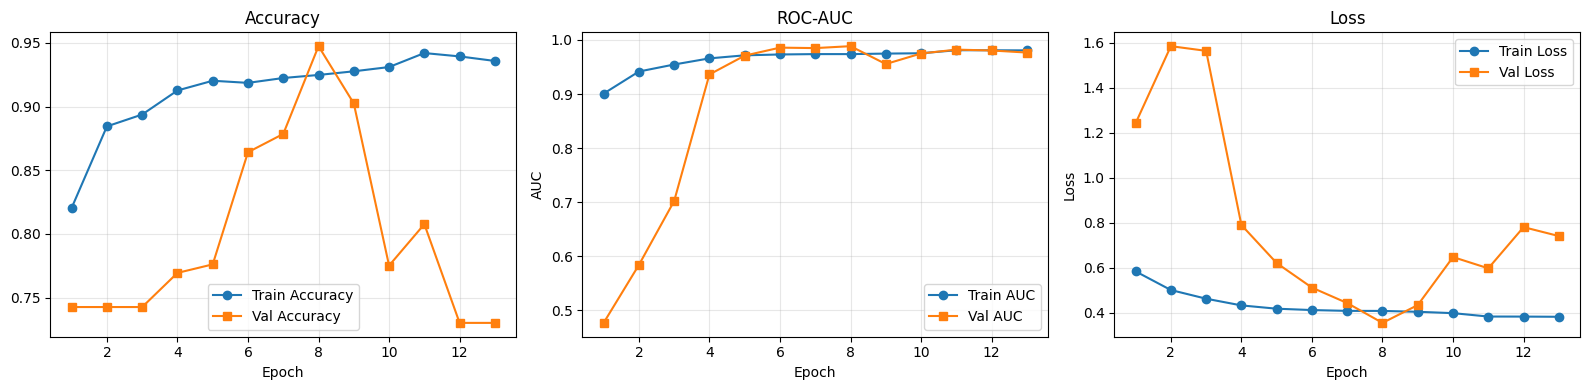

In [8]:
 # 1. Unseen Test Set Evaluation
test_data.reset()
test_loss, test_acc, test_auc = model.evaluate(test_data, verbose=1)
print(f"\n✅ Test Accuracy: {test_acc * 100:.2f}%")
print(f"✅ Test ROC-AUC:  {test_auc:.4f}")

# 2. Optimal Decision Cutoff via ROC Curve (Youden's J Statistic)
test_data.reset()
probs = model.predict(test_data, verbose=0).ravel()
fpr, tpr, thresholds = roc_curve(test_data.classes, probs)
optimal_idx = np.argmax(tpr - fpr)
best_threshold = float(thresholds[optimal_idx])
print(f"✅ Optimal Decision Cutoff (Youden's Index): {best_threshold:.4f}")

preds = (probs >= best_threshold).astype(int)

print("\nConfusion Matrix:")
print(confusion_matrix(test_data.classes, preds))
print("\nClassification Report:")
print(classification_report(test_data.classes, preds, target_names=["NORMAL", "PNEUMONIA"], digits=4))

# 3. Triple Overfitting Diagnostic Curves
acc_k = "accuracy" if "accuracy" in history.history else "acc"
val_acc_k = "val_accuracy" if "val_accuracy" in history.history else "val_acc"
auc_k = [k for k in history.history if "auc" in k and not k.startswith("val_")][0]
val_auc_k = [k for k in history.history if "val_auc" in k][0]

epochs_ran = range(1, len(history.history[acc_k]) + 1)
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.plot(epochs_ran, history.history[acc_k], "o-", label="Train Accuracy")
plt.plot(epochs_ran, history.history[val_acc_k], "s-", label="Val Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(epochs_ran, history.history[auc_k], "o-", label="Train AUC")
plt.plot(epochs_ran, history.history[val_auc_k], "s-", label="Val AUC")
plt.title("ROC-AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(epochs_ran, history.history["loss"], "o-", label="Train Loss")
plt.plot(epochs_ran, history.history["val_loss"], "s-", label="Val Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Upload a Chest X-Ray image:


Saving without pneu.jpg to without pneu.jpg

File:       without pneu.jpg
Diagnosis:  PNEUMONIA
Confidence: 85.73%
Score:      0.8573 (Optimal Cutoff: 0.7414)


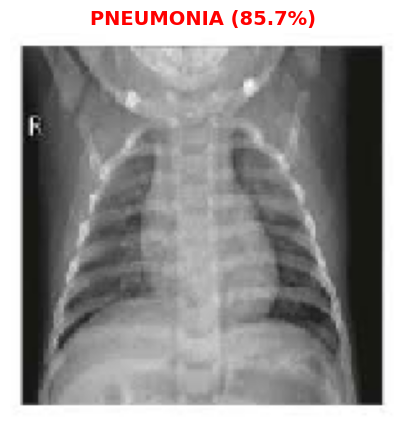

In [10]:
from google.colab import files

print("Upload a Chest X-Ray image:")
uploaded = files.upload()

if uploaded:
    image_name = next(iter(uploaded))

    img = load_img(image_name, target_size=(150, 150))
    img_array = img_to_array(img) / 255.0
    img_batch = np.expand_dims(img_array, axis=0)

    score = float(model.predict(img_batch, verbose=0)[0][0])
    threshold_to_use = best_threshold if "best_threshold" in locals() else 0.50

    is_pneumonia = score >= threshold_to_use
    label = "PNEUMONIA" if is_pneumonia else "NORMAL"
    confidence = (score if is_pneumonia else (1.0 - score)) * 100
    color = "red" if is_pneumonia else "green"

    print("\n" + "=" * 45)
    print(f"File:       {image_name}")
    print(f"Diagnosis:  {label}")
    print(f"Confidence: {confidence:.2f}%")
    print(f"Score:      {score:.4f} (Optimal Cutoff: {threshold_to_use:.4f})")
    print("=" * 45)

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"{label} ({confidence:.1f}%)", color=color, fontsize=14, weight="bold")
    plt.axis("off")
    plt.show()